<a href="https://colab.research.google.com/github/prudhvi-odela/Cancer-Variant-Calling-CADD-Annotation/blob/main/DAY1_whole_slide_imaging.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Day 1 · Whole-slide imaging: from a gigapixel H&E slide to a tumour heatmap

**AI4BIOMED26 · Digital pathology · runs in Google Colab (GPU optional, CPU is fine)**

A pathology slide is far too big for a normal image model (this one is 19,505 × 21,571 pixels, about 0.4 billion pixels).
So we work the way digital pathology does:

| Step | What we do | Why it matters |
| --- | --- | --- |
| 1 | Open the slide at several zoom levels | Look at the whole slide first, then zoom in |
| 2 | Find the tissue | Background glass is wasted computation |
| 3 | Quality control on the tiles | Blurry or empty tiles mislead the model |
| 4 | Extract features with a pretrained CNN | A model that already knows textures and shapes |
| 5 | Train a tile classifier, validated **by tissue block** | A random split leaks neighbouring tiles and inflates the score |
| 6 | Make a slide heatmap | The output a pathologist can check against the H&E |
| 7 | Attention pooling (MIL): the idea, with code | How slide-level labels are used when only the slide is labelled |

**Data.** 10x Genomics FFPE human breast cancer H&E (Janesick et al., *Nat. Commun.* 2023). Each tile has the tumour
share measured on Day 2 by spatial transcriptomics. We call a tile *tumour* when that share is at least 0.5.

**Runtime.** About 5–10 minutes on CPU; faster with a GPU.

## 0. Setup
**In Colab:** the first cell mounts your Drive. Choose the account that owns `AI4BIOMED26` and tick *Select all*.
If mounting fails, the notebook keeps going on local disk and prints how to fix it.

In [ ]:
import os, sys, subprocess, importlib.util
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    from google.colab import drive
    try:
        drive.mount("/content/drive")
        WORK_DIR = Path("/content/drive/MyDrive/AI4BIOMED26")
    except Exception as e:
        print("\n⚠ Google Drive was not mounted:", e)
        print("  Fix: re-run this cell, choose the account that owns the folder and tick 'Select all'.")
        print("  Continuing with local disk — results are LOST when the runtime ends.\n")
        WORK_DIR = Path("/content/AI4BIOMED26")
else:
    WORK_DIR = Path.cwd()
WORK_DIR.mkdir(parents=True, exist_ok=True)
os.chdir(WORK_DIR)
print("Working directory:", WORK_DIR)

REQUIRED = ["openslide", "skimage", "torch", "torchvision", "sklearn", "pandas"]
missing = [m for m in REQUIRED if importlib.util.find_spec(m) is None]
if missing:
    print("Installing:", missing)
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "openslide-python", "openslide-bin",
                    "scikit-image", "scikit-learn", "pandas", "matplotlib"], check=True)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Working directory: /content/drive/MyDrive/AI4BIOMED26


In [ ]:
import warnings
warnings.filterwarnings("ignore")
import json, time, urllib.request
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import openslide

SEED = 0
np.random.seed(SEED)

### Data: the notebook finds it for you
The slide (363 MB) and two tile tables are needed. The notebook looks for them **in this order**, and uses the first that works:

1. **Already in your Drive** at `AI4BIOMED26/data/wsi_breast/`.
2. **A shared folder you added to your Drive** (open the link from the organisers, click **Add shortcut to Drive**). The notebook searches your Drive for it. *This is the recommended way for the workshop.*
3. **A direct download link** (the organisers may set `D1_DATA_URL`) or **Google Drive file ids** (`DRIVE_FILE_IDS`).

When the files are found in Drive, they are copied once to the fast local disk of the session (about one minute), because reading a huge slide straight from Drive is slow.


In [ ]:
import shutil

DATA_URL = os.environ.get("D1_DATA_URL", "")      # 3a. a direct link to a folder that holds the three files
DRIVE_FILE_IDS = {                                 # 3b. or Google Drive file ids (organisers fill these in)
    "breast_HE.tiff": "",
    "tiles_train.csv": "",
    "tiles_test.csv": "",
}
FILES = [("breast_HE.tiff", 300_000_000), ("tiles_train.csv", 1000), ("tiles_test.csv", 1000)]
DRIVE_ROOT = Path("/content/drive/MyDrive")
HOME_DIR = WORK_DIR / "data" / "wsi_breast"       # 1. where your own copy lives
LOCAL_DIR = Path("/content/day1_data") if IN_COLAB else HOME_DIR   # fast local disk used for the analysis


def complete(folder):
    return all((folder / f).exists() and (folder / f).stat().st_size >= n for f, n in FILES)


def find_in_drive():
    """Search your Drive (including shortcuts to shared folders) for a folder that holds the slide."""
    if not DRIVE_ROOT.exists():
        return None
    for pattern in ("*/breast_HE.tiff", "*/*/breast_HE.tiff", "*/*/*/breast_HE.tiff"):
        for hit in sorted(DRIVE_ROOT.glob(pattern)):
            if complete(hit.parent):
                return hit.parent
    return None


DATA_DIR = None
if complete(HOME_DIR):
    source = HOME_DIR
    print("✓ found your own copy:", source)
else:
    source = find_in_drive()
    if source:
        print("✓ found the shared folder in your Drive:", source)

if source is None and DATA_URL:                    # 3a. direct link
    HOME_DIR.mkdir(parents=True, exist_ok=True)
    for f, _ in FILES:
        print("downloading", f)
        urllib.request.urlretrieve(f"{DATA_URL.rstrip('/')}/{f}", HOME_DIR / f)
    source = HOME_DIR
if source is None and all(DRIVE_FILE_IDS.values()):  # 3b. Drive file ids
    import gdown
    HOME_DIR.mkdir(parents=True, exist_ok=True)
    for f, fid in DRIVE_FILE_IDS.items():
        print("downloading", f)
        gdown.download(id=fid, output=str(HOME_DIR / f), quiet=True)
    source = HOME_DIR

if source is None or not complete(source):
    raise SystemExit("The Day 1 data was not found.\n"
                     "  1. Open the data folder link from the organisers.\n"
                     "  2. Click 'Add shortcut to Drive' (choose My Drive).\n"
                     "  3. Run this cell again.")

if source != LOCAL_DIR:                            # copy once to the fast local disk
    LOCAL_DIR.mkdir(parents=True, exist_ok=True)
    for f, _ in FILES:
        if not (LOCAL_DIR / f).exists():
            print("copying", f, "to local disk ...")
            shutil.copy(source / f, LOCAL_DIR / f)
DATA_DIR = LOCAL_DIR
print(sorted(p.name for p in DATA_DIR.iterdir()))

PARAMS = dict(
    min_tissue=0.6,     # keep a tile only if at least 60 % of it is tissue
    blur_min=20.0,      # reject tiles whose sharpness is below this (out of focus)
    tumour_cut=0.5,     # a tile is "tumour" when its measured tumour share is at least this
)
PARAMS


✓ found the shared folder in your Drive: /content/drive/MyDrive/AI4BIOMED26/data
['breast_HE.tiff', 'tiles_test.csv', 'tiles_train.csv']


{'min_tissue': 0.6, 'blur_min': 20.0, 'tumour_cut': 0.5}

## 1 · Open the slide
A whole-slide file stores the image as a **pyramid**: the same picture at several zoom levels. We never load the full
resolution at once; we read regions.

level sizes: ((19505, 21571), (9752, 10785), (4876, 5392), (2438, 2696), (1219, 1348), (609, 674), (304, 337), (152, 168))
resolution: 0.430 µm per pixel · slide 8.39 × 9.28 mm


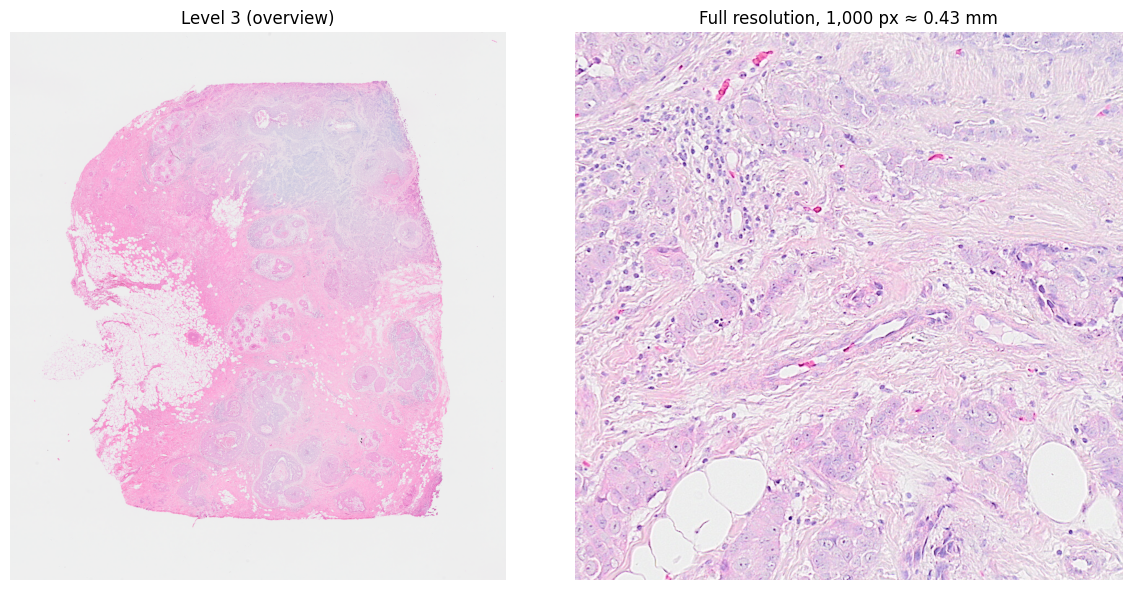

In [ ]:
slide = openslide.OpenSlide(str(DATA_DIR / "breast_HE.tiff"))
mpp = float(slide.properties.get("openslide.mpp-x", 0.4302))
print("level sizes:", slide.level_dimensions)
print(f"resolution: {mpp:.3f} µm per pixel · slide {slide.dimensions[0]*mpp/1000:.2f} × {slide.dimensions[1]*mpp/1000:.2f} mm")

LEVEL = 3
thumb = np.array(slide.read_region((0, 0), LEVEL, slide.level_dimensions[LEVEL]).convert("RGB"))
ds = slide.level_downsamples[LEVEL]
fig, ax = plt.subplots(1, 2, figsize=(12, 6))
ax[0].imshow(thumb); ax[0].set_title(f"Level {LEVEL} (overview)")
x0, y0, s = 9000, 4000, 1000                       # a 1,000-px region at full resolution
ax[1].imshow(slide.read_region((x0, y0), 0, (s, s)).convert("RGB")); ax[1].set_title("Full resolution, 1,000 px ≈ 0.43 mm")
for a in ax: a.axis("off")
plt.tight_layout(); plt.show()

**Try it:** change `LEVEL` and `x0, y0`. Which level shows the tumour nests best? What is the smallest structure you
can resolve at full resolution?

## 2 · Find the tissue
Tissue is pink-purple, glass is white. Colour saturation separates them (Otsu threshold).

tissue covers 21% of the overview image


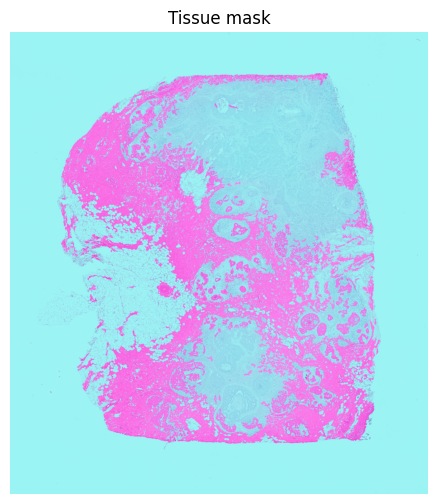

In [ ]:
from skimage.color import rgb2hsv
from skimage.filters import threshold_otsu
from skimage.morphology import remove_small_objects, binary_opening, disk

sat = rgb2hsv(thumb)[..., 1]
tissue = remove_small_objects(binary_opening(sat > threshold_otsu(sat), disk(2)), 200)
print(f"tissue covers {tissue.mean():.0%} of the overview image")
plt.figure(figsize=(6, 6)); plt.imshow(thumb); plt.imshow(tissue, alpha=0.35, cmap="cool")
plt.title("Tissue mask"); plt.axis("off"); plt.show()

## 3 · Tiles and quality control
Every tile is 224 × 224 pixels (about 96 µm). Two checks decide whether a tile is usable:
**enough tissue inside**, and **sharp enough** (out-of-focus tiles have little edge detail).

training tiles: 2182 (in 8 blocks) · test tiles: 2188 (in 8 blocks, labels hidden)
kept training tiles: 1597/2182 · kept test tiles: 1436/2188


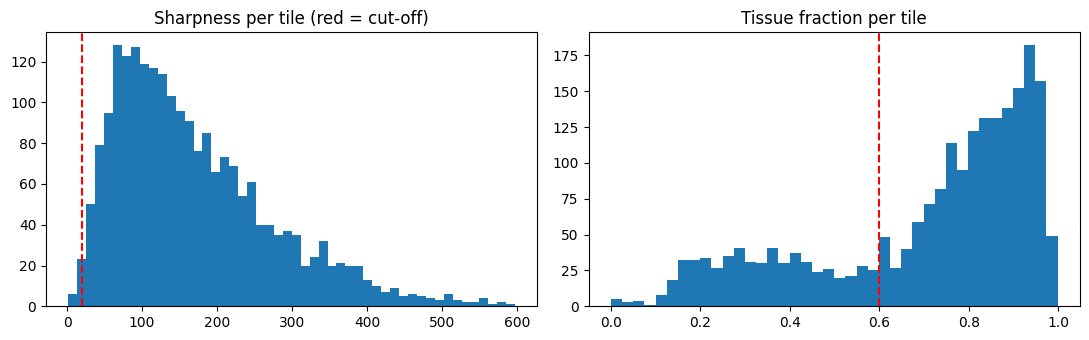

In [ ]:
from skimage.color import rgb2gray
from scipy import ndimage as ndi

train_t = pd.read_csv(DATA_DIR / "tiles_train.csv")
test_t = pd.read_csv(DATA_DIR / "tiles_test.csv")
TILE = int(train_t["size"].iloc[0])
print(f"training tiles: {len(train_t)} (in {train_t.block.nunique()} blocks) · test tiles: {len(test_t)} "
      f"(in {test_t.block.nunique()} blocks, labels hidden)")

def tile_qc(x, y):
    arr = np.asarray(slide.read_region((int(x), int(y)), 0, (TILE, TILE)).convert("RGB"))
    tissue_frac = (rgb2hsv(arr)[..., 1] > 0.08).mean()
    sharpness = ndi.laplace(rgb2gray(arr)).var() * 1e4       # scaled Laplacian variance
    return tissue_frac, sharpness

qc_train = np.array([tile_qc(x, y) for x, y in train_t[["x", "y"]].values])
train_t[["tissue_frac", "sharpness"]] = qc_train
qc_test = np.array([tile_qc(x, y) for x, y in test_t[["x", "y"]].values])
test_t[["tissue_frac", "sharpness"]] = qc_test

ok_train = (train_t.tissue_frac >= PARAMS["min_tissue"]) & (train_t.sharpness >= PARAMS["blur_min"])
ok_test = (test_t.tissue_frac >= PARAMS["min_tissue"]) & (test_t.sharpness >= PARAMS["blur_min"])
print(f"kept training tiles: {ok_train.sum()}/{len(train_t)} · kept test tiles: {ok_test.sum()}/{len(test_t)}")

fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
ax[0].hist(train_t.sharpness, bins=50); ax[0].axvline(PARAMS["blur_min"], color="r", ls="--")
ax[0].set_title("Sharpness per tile (red = cut-off)")
ax[1].hist(train_t.tissue_frac, bins=40); ax[1].axvline(PARAMS["min_tissue"], color="r", ls="--")
ax[1].set_title("Tissue fraction per tile")
plt.tight_layout(); plt.show()

**Think about it:** what would happen to the model if you set `blur_min` to 0? Which blurry tiles would it learn from,
and would that hurt the test blocks?

In [ ]:
train_t, test_t = train_t[ok_train].reset_index(drop=True), test_t[ok_test].reset_index(drop=True)
train_t["tumour_label"] = (train_t["tumour"] >= PARAMS["tumour_cut"]).astype(int)
print(f"tumour tiles in training: {train_t.tumour_label.mean():.0%}")

tumour tiles in training: 22%


## 4 · Features from a pretrained CNN
We pass each tile through ResNet-18 (trained on ImageNet photographs) and keep its 512 numbers. It already knows edges,
textures and cell-like shapes, so we need far fewer labels than training from scratch.
*Pathology foundation models (Phikon, UNI, CONCH) usually give better features; they need a Hugging Face account.*

In [ ]:
import torch, torchvision
from torchvision import transforms
torch.manual_seed(SEED)
device = "cuda" if torch.cuda.is_available() else "cpu"
net = torchvision.models.resnet18(weights=torchvision.models.ResNet18_Weights.IMAGENET1K_V1)
net.fc = torch.nn.Identity(); net = net.eval().to(device)
prep = transforms.Compose([transforms.ToTensor(), transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])])

@torch.no_grad()
def embed(xy, batch=64):
    out = []
    for i in range(0, len(xy), batch):
        imgs = torch.stack([prep(slide.read_region((int(x), int(y)), 0, (TILE, TILE)).convert("RGB")) for x, y in xy[i:i+batch]])
        out.append(net(imgs.to(device)).cpu().numpy())
    return np.concatenate(out)

t0 = time.time()
F_train = embed(train_t[["x", "y"]].values)
F_test = embed(test_t[["x", "y"]].values)
print(f"features: train {F_train.shape}, test {F_test.shape} in {time.time()-t0:.0f} s on {device}")

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 109MB/s]


features: train (1597, 512), test (1436, 512) in 325 s on cpu


## 5 · Train a tile classifier — validated by tissue block
Validation leaves out **whole tissue blocks**, so the score is honest: the model is tested on a region it never saw.

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import GroupKFold, KFold, cross_val_predict
from sklearn.metrics import roc_auc_score

y = train_t.tumour_label.values
groups = train_t.block.values
clf = make_pipeline(StandardScaler(), LogisticRegression(C=0.05, max_iter=3000, class_weight="balanced"))
p_block = cross_val_predict(clf, F_train, y, groups=groups, cv=GroupKFold(n_splits=4), method="predict_proba")[:, 1]
p_rand = cross_val_predict(clf, F_train, y, cv=KFold(5, shuffle=True, random_state=0), method="predict_proba")[:, 1]
auc_block, auc_rand = roc_auc_score(y, p_block), roc_auc_score(y, p_rand)
print(f"AUROC, validated by block (honest):          {auc_block:.3f}")
print(f"AUROC, random tile split (too optimistic):   {auc_rand:.3f}")

AUROC, validated by block (honest):          0.954
AUROC, random tile split (too optimistic):   0.979


**Read the two numbers.** The random split is higher because neighbouring tiles look alike: the model partly remembers
the same region. Always report the **by-block** number.

In [ ]:
clf.fit(F_train, y)
test_t["tumour_prob"] = clf.predict_proba(F_test)[:, 1]
test_t.to_csv(WORK_DIR / "results_day1_test_predictions.csv", index=False)
print("saved", len(test_t), "test tile predictions")

saved 1436 test tile predictions


## 6 · Slide heatmap
Each test tile is coloured by its predicted tumour probability and drawn at its position on the slide.

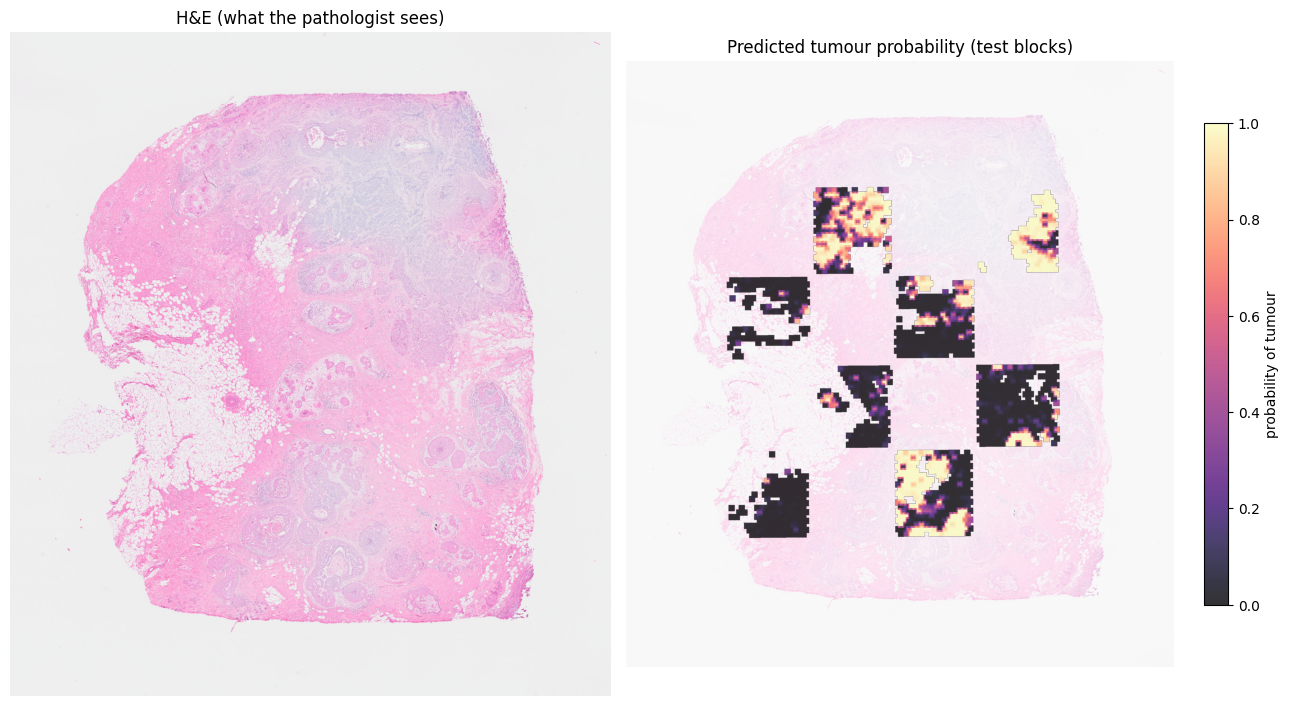

In [ ]:
heat = np.full(thumb.shape[:2], np.nan)
cnt = np.zeros(thumb.shape[:2])
acc = np.zeros(thumb.shape[:2])
for x, y_, p in test_t[["x", "y", "tumour_prob"]].values:
    r0, c0 = int(y_ / ds), int(x / ds)
    r1, c1 = max(r0 + 1, int((y_ + TILE) / ds)), max(c0 + 1, int((x + TILE) / ds))
    acc[r0:r1, c0:c1] += p; cnt[r0:r1, c0:c1] += 1
heat = np.where(cnt > 0, acc / np.maximum(cnt, 1), np.nan)

fig, ax = plt.subplots(1, 2, figsize=(13, 7))
ax[0].imshow(thumb); ax[0].set_title("H&E (what the pathologist sees)"); ax[0].axis("off")
ax[1].imshow(thumb, alpha=0.4)
im = ax[1].imshow(heat, cmap="magma", vmin=0, vmax=1, alpha=0.8)
ax[1].set_title("Predicted tumour probability (test blocks)"); ax[1].axis("off")
plt.colorbar(im, ax=ax[1], fraction=0.04, label="probability of tumour")
plt.tight_layout(); plt.show()

**Check it like a pathologist:** do the bright areas match the tumour nests on the H&E? Where are the false alarms
(for example stroma or folds)? Zoom in with `slide.read_region`.

## 7 · Attention pooling (multiple-instance learning)
Often a slide has only one label ("tumour / no tumour"), but thousands of tiles. **Multiple-instance learning (MIL)**
treats the slide as a bag of tiles and learns which tiles matter. *Attention-MIL* gives each tile a weight and
averages the tile features with those weights. The weights are the explanation: they form a heatmap.

Below is the pooling in a few lines. To **train** it you need many slides with slide-level labels (for example the
TCGA-BRCA breast cohort, about 1,100 slides). With one slide the code shows the mechanics only.

In [ ]:
class AttentionPool(torch.nn.Module):
    def __init__(self, d=512, h=64):
        super().__init__()
        self.V = torch.nn.Linear(d, h); self.U = torch.nn.Linear(d, h); self.w = torch.nn.Linear(h, 1)
        self.clf = torch.nn.Linear(d, 1)

    def forward(self, bag):                                        # bag: (n_tiles, 512)
        a = self.w(torch.tanh(self.V(bag)) * torch.sigmoid(self.U(bag)))   # one score per tile
        a = torch.softmax(a, dim=0)                                # weights sum to 1 over the slide
        slide_vec = (a * bag).sum(0)                               # attention-weighted average of tiles
        return torch.sigmoid(self.clf(slide_vec)), a.squeeze(1)

torch.manual_seed(SEED)
mil = AttentionPool()
bag = torch.tensor(F_test, dtype=torch.float32)
slide_prob, attn = mil(bag)
print(f"untrained slide score: {float(slide_prob):.3f} (random weights: not meaningful yet)")
print(f"attention weights sum to {float(attn.sum()):.3f}; largest single tile weight {float(attn.max()):.4f}")

untrained slide score: 0.373 (random weights: not meaningful yet)
attention weights sum to 1.000; largest single tile weight 0.0009


**Exercise:** after training on many slides, `attn` gives one weight per tile. Draw it on the slide the same way as
the heatmap above. Are the high-attention tiles the tumour tiles?

## 8 · Save a summary

In [ ]:
summary = {
    "training_tiles_kept": int(len(train_t)), "test_tiles_kept": int(len(test_t)),
    "tumour_share_in_training": round(float(y.mean()), 3),
    "auroc_validated_by_block": round(float(auc_block), 3),
    "auroc_random_split_too_optimistic": round(float(auc_rand), 3),
    "resolution_um_per_px": mpp, "tile_px": TILE, "device": device,
}
json.dump(summary, open(WORK_DIR / "results_day1_summary.json", "w"), indent=2)
print(json.dumps(summary, indent=2))

{
  "training_tiles_kept": 1597,
  "test_tiles_kept": 1436,
  "tumour_share_in_training": 0.219,
  "auroc_validated_by_block": 0.954,
  "auroc_random_split_too_optimistic": 0.979,
  "resolution_um_per_px": 0.43023941058545245,
  "tile_px": 224,
  "device": "cpu"
}


## Limitations (say these when you present)
* **One slide, one patient.** The classifier learned this tumour, not breast cancer in general.
* **Labels come from gene expression**, so they are approximate near tumour edges.
* **Scanners and stains change the image.** Features shift between labs; stain normalisation helps.
* **Attention is not proof.** High-attention tiles show where the model looked, not why it decided.

## Exercises
1. Change `min_tissue` to 0.3 and 0.9. How many tiles are kept, and does the by-block score change?
2. Change `tumour_cut` to 0.2 and 0.8. Which threshold gives the best by-block score, and what does that mean?
3. Replace ResNet-18 with another torchvision model (e.g. `efficientnet_b0`). Which is better by block?